# 06. 학습 사전 검증과 Baseline

기존 3단계 코드·데이터·Notebook을 유지하고 새 모델을 `outputs/stage4/`에 저장했습니다. 600 원시시간 구간을 먼저 실행했으며 소규모 점검 후 전체 처리된 학습 세트로 확장했습니다. 아래 코드는 실제 학습 산출물과 예측 점수를 읽습니다. 원본 전체를 한 번에 읽지 않았고, 해당 타깃의 준비된 처리 데이터만 학습 행렬로 만들었습니다.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.model_common import OUT,configs,read_json
from src.model_summary import collect,selected_per_family
from src import model_plots as plots
plots.setup()
objects,metrics=collect()
audit=read_json(OUT/"preflight.json")
pd.set_option("display.max_columns",40)
print("실행 환경:",sys.executable)
print("실제 학습 완료 모델을 읽음. 기존 점수와 임계값을 재사용하며 평가 세트로 재조정하지 않음.")

실행 환경: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
실제 학습 완료 모델을 읽음. 기존 점수와 임계값을 재사용하며 평가 세트로 재조정하지 않음.


## 시간 해석과 데이터 대표성

[공식 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)의 초 예시와 [Huang 등(2018) 5.3절](https://papers.phmsociety.org/index.php/phmconf/article/download/590/phmc_18_590)의 약 4초 기록 설명을 실제 원본 차분·TTF 감소와 대조했습니다. 이 근거들은 초 해석을 지지합니다. 외부 시계 보정은 검증하지 않았으며 기존 raw 컬럼명과 데이터 정책 파일은 변경하지 않았습니다. **h600raw는 이 해석에서 약 10분**입니다.

전체 82,071,907개 시각에서 60 원시단위 bin의 첫 시각을 고르고, 과거 600 이력·관측 밀도·유한 특징을 요구한 뒤 12개 타깃 중 하나라도 알려진 행을 남겨 1,466,770행이 되었습니다. 이것은 무작위 대표 표본이 아닙니다. 미래 관측의 지속 여부와 TTF 결측으로 조건화되어 공백 근처 고장·후기 정상 상태가 과소대표됩니다. 클래스별 재표본화는 하지 않았지만 필터의 실제 보존율은 유형/상태별로 다릅니다.

In [2]:
time_check=pd.DataFrame(audit["time_evidence"])
display(time_check)
assert (time_check.same_event_pairs==time_check.ttf_decrease_matches_dt).all()
old=read_json(ROOT/"reports/local/dataset_v1/dataset_summary.json")
full=pd.DataFrame(old["full_counts"]).query("fault_code=='any' and horizon_raw==600")
ready=pd.DataFrame(old["ready_counts"]).query("fault_code=='any' and horizon_raw==600")
retention=pd.DataFrame({"전체 알려진 관측":full[["positive","negative"]].sum(),"학습 후보 보존":ready[["positive","negative"]].sum()})
retention["보존율"]=retention["학습 후보 보존"]/retention["전체 알려진 관측"]
display(retention)
display(pd.DataFrame(audit["distributions"]).query("horizon==600"))
e=pd.DataFrame(audit["events"])
display(e[e.horizon==600].groupby(["scheme","split","fault_code"]).event_key.nunique().rename("평가 가능한 고유 유형 이벤트 수").to_frame())
display(Markdown("장비 평가의 누출 이벤트는 4건으로 매우 적습니다. 고정 분할을 섞거나 바꾸지 않았습니다. 다음 단계에서는 장비 그룹 교차검증으로 변동성을 확인할 수 있으나 이번 실험에는 적용하지 않았습니다."))

,file,fault,rows,mode_dt,same_event_pairs,ttf_decrease_matches_dt
0,01_M01_DC_train.csv,FlowCool Pressure Dropped Below Limit,10000,4.0,9999,9999
1,01_M01_DC_train.csv,Flowcool Pressure Too High Check Flowcool Pump,10000,4.0,9999,9999
2,01_M01_DC_train.csv,Flowcool leak,10000,4.0,9999,9999
3,01_M02_DC_train.csv,FlowCool Pressure Dropped Below Limit,10000,4.0,9999,9999
4,01_M02_DC_train.csv,Flowcool Pressure Too High Check Flowcool Pump,10000,4.0,9999,9999
5,01_M02_DC_train.csv,Flowcool leak,10000,4.0,9999,9999
6,02_M01_DC_train.csv,FlowCool Pressure Dropped Below Limit,10000,4.0,9999,9999
7,02_M01_DC_train.csv,Flowcool Pressure Too High Check Flowcool Pump,10000,4.0,9999,9999
8,02_M01_DC_train.csv,Flowcool leak,10000,4.0,9999,9999
9,02_M02_DC_train.csv,FlowCool Pressure Dropped Below Limit,10000,4.0,9999,9999


,전체 알려진 관측,학습 후보 보존,보존율
positive,49268,2249,0.045648
negative,14377472,572674,0.039831


,split,candidates,positive,negative,unknown,scheme,horizon
3,evaluation,171733,345,30125,141263,split_tool,600
4,validation,185120,363,75128,109629,split_tool,600
5,train,1109917,1541,467421,640955,split_tool,600
13,evaluation,213514,475,9890,203149,split_time,600
14,validation,295132,442,83682,211008,split_time,600
15,purged,236,0,67,169,split_time,600
16,train,957888,1332,479035,477521,split_time,600


평가 가능한 고유 유형 이벤트 수
scheme     split      fault_code                    
split_time evaluation f1                          35
                      f2                          12
                      f3                           9
           train      f1                          85
                      f2                          34
                      f3                          38
           validation f1                          36
                      f2                          13
                      f3                           7
split_tool evaluation f1                          30
                      f2                          11
                      f3                           4
           train      f1                         108
                      f2                          30
                      f3                          43
           validation f1                          18
                      f2                          18
                      f3                           7

장비 평가의 누출 이벤트는 4건으로 매우 적습니다. 고정 분할을 섞거나 바꾸지 않았습니다. 다음 단계에서는 장비 그룹 교차검증으로 변동성을 확인할 수 있으나 이번 실험에는 적용하지 않았습니다.

## 입력 구성 및 전처리

A는 현재 센서 6개와 recipe/stage로 8개, B는 A에 과거 센서 통계를 추가한 80개, C는 공정 이력 3개를 더한 83개입니다. 모두 현재 또는 과거 기록으로 계산할 수 있습니다. 실제 현장 수집 지연은 미검증입니다. TTF·라벨·미래 기록·Tool/Lot·절대 time·사용량은 주 실험 입력에 없습니다. 유한 특징만 사용하므로 대치·스케일링을 하지 않았습니다. recipe/stage 코드는 숫자로 처리한 트리 기준이며 범주 처리의 최적성은 미검증입니다.

In [3]:
display(pd.DataFrame([(name,len(cols)) for name,cols in configs().items()],columns=["입력 구성","특징 수"]))
for name,cols in configs().items():display(pd.DataFrame({name+" 입력":cols}))
print("소규모 점검:",read_json(OUT/"smoke.json"))
display(Markdown("소규모 점검은 학습 장비 01M01/01M02만 사용해 RF 8개 트리·XGBoost 10회가 실행되는지 확인했습니다. 평가 데이터는 사용하지 않았습니다. 이후 모든 준비된 학습 행으로 고정 설정의 전체 실험을 실행했습니다."))

,입력 구성,특징 수
0,A,8
1,B,80
2,C,83


,A 입력
0,recipe
1,stage
2,FLOWCOOLPRESSURE__current
3,FLOWCOOLFLOWRATE__current
4,IONGAUGEPRESSURE__current
5,ETCHBEAMCURRENT__current
6,ETCHBEAMVOLTAGE__current
7,ETCHSUPPRESSORCURRENT__current


,B 입력
0,recipe
1,stage
2,FLOWCOOLPRESSURE__current
3,FLOWCOOLPRESSURE__mean_60raw
4,FLOWCOOLPRESSURE__std_60raw
...,...
75,ETCHSUPPRESSORCURRENT__std_300raw
76,ETCHSUPPRESSORCURRENT__min_300raw
77,ETCHSUPPRESSORCURRENT__max_300raw
78,ETCHSUPPRESSORCURRENT__delta_mean_300raw


,C 입력
0,recipe
1,stage
2,FLOWCOOLPRESSURE__current
3,FLOWCOOLPRESSURE__mean_60raw
4,FLOWCOOLPRESSURE__std_60raw
...,...
78,ETCHSUPPRESSORCURRENT__delta_mean_300raw
79,ETCHSUPPRESSORCURRENT__rate_mean_300raw
80,stage_zero_fraction_300raw
81,stage_change_count_300raw


소규모 점검: {'rows': 197439, 'positive': 560, 'equipment': ['01M01', '01M02'], 'rf_fit': True, 'xgb_fit': True, 'evaluation_used': False}


소규모 점검은 학습 장비 01M01/01M02만 사용해 RF 8개 트리·XGBoost 10회가 실행되는지 확인했습니다. 평가 데이터는 사용하지 않았습니다. 이후 모든 준비된 학습 행으로 고정 설정의 전체 실험을 실행했습니다.

## Dummy·압력 임계값·Random Forest

Dummy는 학습 양성 비율을 출력하며 임계값은 0.5입니다. 압력 모델은 학습 AP로 방향을 정하고 학습 경험적 CDF로 점수를 변환한 뒤 검증 F1로 임계값을 골랐습니다. CDF 점수는 보정 확률이 아닙니다.

RF는 64개 트리, 깊이 10, 최소 리프 20, balanced_subsample을 사용했습니다. 내부 bootstrap은 학습 세트에만 적용되고 데이터셋의 시간/이벤트 분할은 바꾸지 않습니다. 검증/평가 행은 재표본화하지 않았습니다. RF 임계값도 검증 F1로 정했습니다. 설정은 평가 결과를 보기 전에 고정했고 평가 데이터로 수정하지 않았습니다.

,name,n,positive,precision,recall,f1,pr_auc_ap,roc_auc,tn,fp,fn,tp
137,Dummy,30470,345,NaN,0.000000,0.000000,0.011323,0.500000,30125,0,345,0
140,Pressure,30470,345,0.014155,0.362319,0.027245,0.013591,0.518652,21419,8706,220,125
143,RF_A,30470,345,0.170213,0.069565,0.098765,0.047113,0.583816,30008,117,321,24
146,RF_B,30470,345,NaN,0.000000,0.000000,0.017619,0.597185,30125,0,345,0
149,RF_C,30470,345,0.400000,0.028986,0.054054,0.044049,0.512165,30110,15,335,10


,name,n,positive,precision,recall,f1,pr_auc_ap,roc_auc,tn,fp,fn,tp
50,Dummy,10365,475,NaN,0.000000,0.000000,0.045827,0.500000,9890,0,475,0
53,Pressure,10365,475,NaN,0.000000,0.000000,0.200566,0.567915,9890,0,475,0
56,RF_A,10365,475,0.947368,0.113684,0.203008,0.267084,0.714509,9887,3,421,54
59,RF_B,10365,475,0.415663,0.145263,0.215289,0.191183,0.636709,9793,97,406,69
62,RF_C,10365,475,0.643836,0.098947,0.171533,0.179330,0.636044,9864,26,428,47


정의 불가능한 지표는 NaN/None으로 표시합니다. 예를 들어 경보가 없는 Dummy의 Precision은 정의되지 않지만, 양성 정답이 있는 평가에서 F1=0은 실제 계산 결과입니다. Accuracy는 보조 지표로만 저장했습니다.

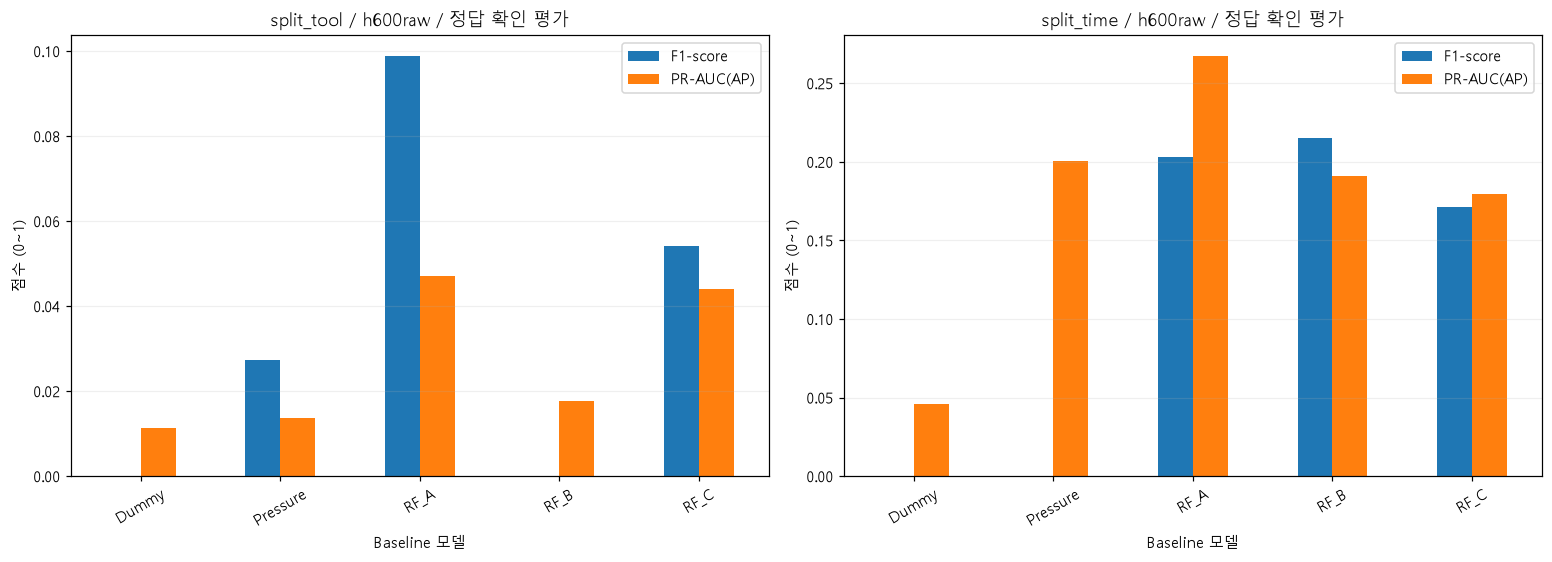

압력 순위의 AP와 검증 임계값의 F1은 다르게 움직일 수 있습니다. 특히 시간 평가에서 압력 AP가 높아도 고정 임계값의 경보는 없어 F1=0입니다. 평가 결과에 맞춰 임계값을 바꾸지 않았습니다.

In [4]:
from src.train_baseline import train
for scheme in ("split_tool","split_time"):
    cached=train(scheme,600)
    table=metrics[(metrics.scheme==scheme)&(metrics.horizon==600)&(metrics.split=="evaluation")&(~metrics.identity_diagnostic)&(~metrics.name.str.startswith("XGB"))]
    display(table[["name","n","positive","precision","recall","f1","pr_auc_ap","roc_auc","tn","fp","fn","tp"]])
display(Markdown("정의 불가능한 지표는 NaN/None으로 표시합니다. 예를 들어 경보가 없는 Dummy의 Precision은 정의되지 않지만, 양성 정답이 있는 평가에서 F1=0은 실제 계산 결과입니다. Accuracy는 보조 지표로만 저장했습니다."))
fig,axes=plt.subplots(1,2,figsize=(14,5),layout="constrained")
for ax,scheme in zip(axes,("split_tool","split_time")):
    table=metrics[(metrics.scheme==scheme)&(metrics.horizon==600)&(metrics.split=="evaluation")&(~metrics.identity_diagnostic)&(~metrics.name.str.startswith("XGB"))].set_index("name")
    table[["f1","pr_auc_ap"]].rename(columns={"f1":"F1-score","pr_auc_ap":"PR-AUC(AP)"}).plot.bar(ax=ax)
    ax.set(title=f"{scheme} / h600raw / 정답 확인 평가",xlabel="Baseline 모델",ylabel="점수 (0~1)");ax.tick_params(axis="x",rotation=30);ax.legend();ax.grid(axis="y",alpha=.2)
plots.save(fig,"baseline_comparison")
display(Markdown("압력 순위의 AP와 검증 임계값의 F1은 다르게 움직일 수 있습니다. 특히 시간 평가에서 압력 AP가 높아도 고정 임계값의 경보는 없어 F1=0입니다. 평가 결과에 맞춰 임계값을 바꾸지 않았습니다."))